# Workshop 3 - Silver data quality review

Kevin David Rincon Valencia and Pablo Garzon Gomez - Team 9.

We follow the course EDA sequence: inspect a DataFrame, check types and missing
values, describe distributions, compare outlier methods, inspect relationships,
and document curation decisions before Gold. All data comes from saved files.

The quality population is the frozen 13-export review (2021-2025, one GHCN station).
The current Airflow Gold batch also includes two later replay exports; both
selections reconcile to the same 19,039 source records. Repeated exports do not
represent additional weather events. Raw and Silver values are preserved.

Course sources: [EDA and curation](https://github.com/EngAndres/ud-public/blob/d938aa2acb2d33067588aece5bb9e10f6951a692/courses/data-analysis-programming/notebooks/eda_data_curation.ipynb),
[visualizations](https://github.com/EngAndres/ud-public/blob/d938aa2acb2d33067588aece5bb9e10f6951a692/courses/data-analysis-programming/notebooks/eda_visualizations.ipynb),
and [automatic profiling](https://github.com/EngAndres/ud-public/blob/d938aa2acb2d33067588aece5bb9e10f6951a692/courses/data-analysis-programming/notebooks/eda_ydata_profiling.ipynb).
The reviewed latest-file hashes are recorded in `academic_materials.json`.
Run using the separate `requirements-workshop3-eda.in` environment; this notebook
does not install packages or run weather requests.

In [1]:
from pathlib import Path
import hashlib
import json
import math
import numpy as np
from scipy import stats as sp_stats
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "workshop_2/evidence/historical_airflow_runs.json").exists())
out = root / "workshop_3/evidence/eda_20261124"
out.mkdir(parents=True, exist_ok=True)
receipt_paths = [root / "workshop_2/evidence" / name for name in
                 ["historical_airflow_runs.json", "replay_airflow_runs.json"]]
files = {}
for path in receipt_paths:
    receipt = json.loads(path.read_text())
    for run in receipt["runs"]:
        assert run["bronze"]["state"] == run["silver"]["state"] == "success"
        export = run["output"]["silver"]
        files[export["path"]] = export
frames, hashes = [], {}
frozen_register_path = root / "workshop_3/evidence/silver_review.json"
frozen_register_sha256 = hashlib.sha256(frozen_register_path.read_bytes()).hexdigest().upper()
for name, export in sorted(files.items()):
    path = root / name
    digest = hashlib.sha256(path.read_bytes()).hexdigest().upper()
    assert digest == export["sha256"]
    df = pd.read_parquet(path)
    assert len(df) == export["rows"]
    df["export_path"] = name
    frames.append(df)
    hashes[name] = digest
raw = pd.concat(frames, ignore_index=True)
print("Verified exports:", len(files), "| Snapshot rows:", len(raw))
display(raw.head())

Verified exports: 13 | Snapshot rows: 22553


,record_id,source,source_key,event_type,observed_at_utc,observed_date,latitude,longitude,severity_value,severity_unit,magnitude_type,quality_attributes,source_content_sha256,capture_sha256,run_id,capture_id,source_line,revision_id,export_path
0,2670,ghcn_daily,USW00013967/2021-01-01/PRCP,PRCP,NaT,2021-01-01,35.38843,-97.60035,15.2,mm,None,",,W,2400",d774ca58c09fa9a69c146ce52b7079f404c8c96185b579...,3af94b20dfcb8276a79c6941a217569c9761470e790d39...,17,17,2,7455,data/curated/silver/ghcn_daily_20261117_020238...
1,2671,ghcn_daily,USW00013967/2021-01-01/TMAX,TMAX,NaT,2021-01-01,35.38843,-97.60035,1.1,degC,None,",,W",d774ca58c09fa9a69c146ce52b7079f404c8c96185b579...,3af94b20dfcb8276a79c6941a217569c9761470e790d39...,17,17,2,7456,data/curated/silver/ghcn_daily_20261117_020238...
2,2672,ghcn_daily,USW00013967/2021-01-01/TMIN,TMIN,NaT,2021-01-01,35.38843,-97.60035,-1.0,degC,None,",,W",d774ca58c09fa9a69c146ce52b7079f404c8c96185b579...,3af94b20dfcb8276a79c6941a217569c9761470e790d39...,17,17,2,7457,data/curated/silver/ghcn_daily_20261117_020238...
3,2673,ghcn_daily,USW00013967/2021-01-02/PRCP,PRCP,NaT,2021-01-02,35.38843,-97.60035,0.3,mm,None,",,W,2400",fbd850d836da22b057eddb8d0586b85425c26203de8a93...,3af94b20dfcb8276a79c6941a217569c9761470e790d39...,17,17,3,7458,data/curated/silver/ghcn_daily_20261117_020238...
4,2674,ghcn_daily,USW00013967/2021-01-02/TMAX,TMAX,NaT,2021-01-02,35.38843,-97.60035,5.6,degC,None,",,W",fbd850d836da22b057eddb8d0586b85425c26203de8a93...,3af94b20dfcb8276a79c6941a217569c9761470e790d39...,17,17,3,7459,data/curated/silver/ghcn_daily_20261117_020238...


## 0. Inspect the loaded DataFrame

These are saved Silver snapshots. Numeric record/run IDs are identifiers, so
they are excluded from weather distribution summaries.

In [2]:
df_raw = raw
print("Rows and columns:", df_raw.shape)
df_raw.info()
display(df_raw[["source", "event_type", "observed_at_utc", "observed_date",
                "severity_value", "severity_unit"]].head())
display(df_raw.dtypes.to_frame("dtype"))
print("Fully repeated rows:", int(df_raw.duplicated().sum()))
print("Repeated source/key rows:", int(df_raw.duplicated(["source", "source_key"]).sum()))
# Snapshot lineage is reconciled in the next section before counting source records.

Rows and columns: (22553, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22553 entries, 0 to 22552
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   record_id              22553 non-null  int64              
 1   source                 22553 non-null  object             
 2   source_key             22553 non-null  object             
 3   event_type             22553 non-null  object             
 4   observed_at_utc        14885 non-null  datetime64[us, UTC]
 5   observed_date          7668 non-null   object             
 6   latitude               14912 non-null  float64            
 7   longitude              14912 non-null  float64            
 8   severity_value         14219 non-null  float64            
 9   severity_unit          14219 non-null  object             
 10  magnitude_type         3356 non-null   object             
 11  quality_attributes     7

,source,event_type,observed_at_utc,observed_date,severity_value,severity_unit
0,ghcn_daily,PRCP,NaT,2021-01-01,15.2,mm
1,ghcn_daily,TMAX,NaT,2021-01-01,1.1,degC
2,ghcn_daily,TMIN,NaT,2021-01-01,-1.0,degC
3,ghcn_daily,PRCP,NaT,2021-01-02,0.3,mm
4,ghcn_daily,TMAX,NaT,2021-01-02,5.6,degC


,dtype
record_id,int64
source,object
source_key,object
event_type,object
observed_at_utc,"datetime64[us, UTC]"
observed_date,object
latitude,float64
longitude,float64
severity_value,float64
severity_unit,object


Fully repeated rows: 0
Repeated source/key rows: 3514


## 1. Reconcile repeated exports

The recorded run ID orders successful runs within this local database history.
For each source/key we retain the latest observed snapshot by run ID. Before
selection, copies of the same key/revision must agree on content. This rule is
not a general ordering across independent databases. An older revision can be
observed again by a later run, so revision ID alone is not the selection rule.

In [3]:
keys = ["source", "source_key"]
conflicts = raw.groupby(keys + ["revision_id"])["source_content_sha256"].nunique()
assert not conflicts.gt(1).any(), "Conflicting snapshot lineage"
canonical = (raw.sort_values(["run_id", "export_path"])
             .drop_duplicates(keys, keep="last").copy())
assert not canonical.duplicated(keys).any()
inventory = raw.groupby("source").size().rename("snapshot_rows").to_frame()
inventory["business_records"] = canonical.groupby("source").size()
inventory["repeated_snapshot_rows"] = inventory["snapshot_rows"] - inventory["business_records"]
display(inventory)
display(canonical.groupby(["source", "event_type", "severity_unit"], dropna=False).size().to_frame("records"))

,snapshot_rows,business_records,repeated_snapshot_rows
source,,,
ghcn_daily,7668,5478,2190
noaa_storm_events,14885,13561,1324


records
source            event_type              severity_unit         
ghcn_daily        PRCP                    mm                1826
                  TMAX                    degC              1826
                  TMIN                    degC              1826
noaa_storm_events Blizzard                NaN                  2
                  Cold/Wind Chill         NaN                276
                  Dense Fog               NaN                  1
                  Drought                 NaN               1888
                  Dust Storm              NaN                  8
                  Excessive Heat          NaN               1499
                  Extreme Cold/Wind Chill NaN                118
                  Flash Flood             NaN                394
                  Flood                   NaN                129
                  Freezing Fog            NaN                  1
                  Frost/Freeze            NaN                 48
                  Funnel Cloud            NaN                  2
                  Hail                    in                2936
                  Heat                    NaN               2081
                  Heavy Rain              NaN                  1
                  Heavy Snow              NaN                159
                  High Wind               kn                 507
                  Ice Storm               NaN                  4
                  Lightning               NaN                 10
                  Sleet                   NaN                  3
                  Strong Wind             kn                   3
                  Thunderstorm Wind       kn                2492
                  Tornado                 NaN                513
                  Wildfire                NaN                203
                  Winter Storm            NaN                216
                  Winter Weather          NaN                 67

## 2. Missingness depends on record semantics

Daily GHCN records intentionally have no UTC instant. Missing storm points or
magnitudes are not filled with zeros. Compare null rates by source rather than
treating source-inapplicable columns as failed observations.

In [4]:
fields = ["observed_at_utc", "observed_date", "latitude", "longitude",
          "severity_value", "severity_unit", "quality_attributes"]
missing = canonical.groupby("source")[fields].agg(lambda s: s.isna().mean())
display(missing.rename_axis(columns="null fraction"))
daily = canonical[canonical["source"].eq("ghcn_daily")].copy()
daily["station"] = daily["source_key"].str.split("/").str[0]
daily["date"] = pd.to_datetime(daily["observed_date"])
assert daily["observed_at_utc"].isna().all()
assert daily["observed_date"].notna().all()
display(daily.groupby([daily["date"].dt.year, "event_type"])["severity_value"].count().unstack())
qc = daily["quality_attributes"].fillna("").str.split(",").str[1].fillna("")
display(qc.value_counts().rename_axis("Provider quality flag").to_frame("records"))

null fraction,observed_at_utc,observed_date,latitude,longitude,severity_value,severity_unit,quality_attributes
source,,,,,,,
ghcn_daily,1.0,0.0,0.00000,0.00000,0.000000,0.000000,0.0
noaa_storm_events,0.0,1.0,0.52238,0.52238,0.562127,0.562127,1.0


event_type,PRCP,TMAX,TMIN
date,,,
2021,365,365,365
2022,365,365,365
2023,365,365,365
2024,366,366,366
2025,365,365,365


,records
Provider quality flag,
,5478


,source,field,null_count,records,null_percent
0,ghcn_daily,observed_at_utc,5478,5478,100.000000
1,ghcn_daily,observed_date,0,5478,0.000000
2,ghcn_daily,latitude,0,5478,0.000000
3,ghcn_daily,longitude,0,5478,0.000000
4,ghcn_daily,severity_value,0,5478,0.000000
5,ghcn_daily,severity_unit,0,5478,0.000000
6,ghcn_daily,quality_attributes,0,5478,0.000000
7,noaa_storm_events,observed_at_utc,0,13561,0.000000
8,noaa_storm_events,observed_date,13561,13561,100.000000
9,noaa_storm_events,latitude,7084,13561,52.238036


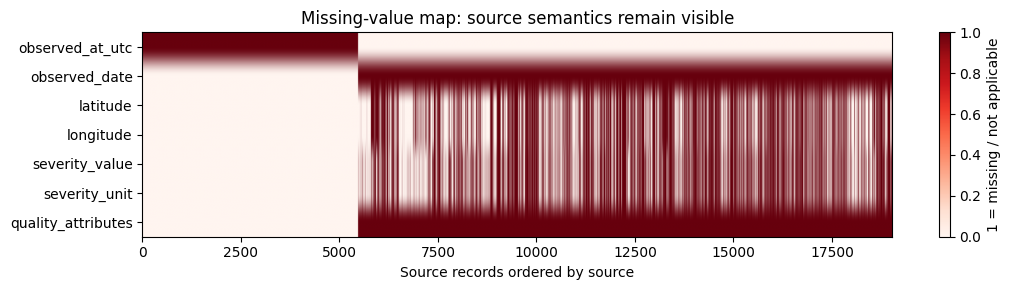

In [5]:
null_rows = []
for source_name, group in canonical.groupby("source"):
    for field in fields:
        null_rows.append({"source": source_name, "field": field,
                          "null_count": int(group[field].isna().sum()),
                          "records": len(group), "null_percent": group[field].isna().mean() * 100})
null_report = pd.DataFrame(null_rows)
display(null_report)
ordered = canonical.sort_values("source")
fig, ax = plt.subplots(figsize=(11, 3))
image = ax.imshow(ordered[fields].isna().astype(int).T, aspect="auto", cmap="Reds", vmin=0, vmax=1)
ax.set_yticks(range(len(fields)), fields)
ax.set(xlabel="Source records ordered by source", title="Missing-value map: source semantics remain visible")
plt.colorbar(image, ax=ax, label="1 = missing / not applicable")
plt.tight_layout(); plt.show()

## 2.1 Station table and quality checks

We align measurements by their actual daily date before comparing PRCP, TMAX
and TMIN. No synthetic date labels or row-position joins are used. An apparent
gap or an outlier is a review finding; it is not automatically an invalid record.

In [6]:
assert not daily.duplicated(["station", "date", "event_type"]).any()
assert daily.station.nunique() == 1
wide = daily.pivot(index="date", columns="event_type", values="severity_value").sort_index()
wide = wide[["PRCP", "TMAX", "TMIN"]]
display(wide.head())
display(wide.describe().round(3))
expected_dates = pd.date_range("2021-01-01", "2025-12-31", freq="D")
missing_dates = expected_dates.difference(wide.index)
checks = pd.DataFrame([
    {"dimension": "Uniqueness", "check": "Duplicate canonical source/key groups",
     "count": int(canonical.duplicated(["source", "source_key"]).sum()), "denominator": len(canonical), "handling": "Reject conflicting snapshots; retain one reviewed record"},
    {"dimension": "Completeness", "check": "Missing station dates in 2021-2025",
     "count": len(missing_dates), "denominator": len(expected_dates), "handling": "Report gaps; do not fabricate measurements"},
    {"dimension": "Validity", "check": "Negative recorded precipitation",
     "count": int(wide.PRCP.lt(0).sum()), "denominator": int(wide.PRCP.notna().sum()), "handling": "Review/quarantine physical invalidity"},
    {"dimension": "Consistency", "check": "TMIN exceeds TMAX on the same source date",
     "count": int(wide.TMIN.gt(wide.TMAX).sum()), "denominator": int(wide[["TMIN", "TMAX"]].notna().all(axis=1).sum()), "handling": "Review paired source values"},
])
display(checks)
# Missingness mechanisms cannot be inferred from a percentage alone.
# Source-inapplicable dates and missing storm magnitudes are retained without imputation.

event_type,PRCP,TMAX,TMIN
date,,,
2021-01-01,15.2,1.1,-1.0
2021-01-02,0.3,5.6,-0.5
2021-01-03,0.0,5.0,-2.1
2021-01-04,0.0,13.3,-2.1
2021-01-05,0.0,14.4,-2.7


event_type,PRCP,TMAX,TMIN
count,1826.000,1826.000,1826.000
mean,2.395,22.946,10.171
std,8.710,10.084,9.748
min,0.000,-15.500,-25.500
25%,0.000,16.100,2.350
50%,0.000,24.400,11.100
75%,0.000,31.100,18.900
max,167.400,43.300,27.800


,dimension,check,count,denominator,handling
0,Uniqueness,Duplicate canonical source/key groups,0,19039,Reject conflicting snapshots; retain one revie...
1,Completeness,Missing station dates in 2021-2025,0,1826,Report gaps; do not fabricate measurements
2,Validity,Negative recorded precipitation,0,1826,Review/quarantine physical invalidity
3,Consistency,TMIN exceeds TMAX on the same source date,0,1826,Review paired source values


## 3. Shape, IQR and Z-score

We use `scipy.stats.skew()` and `scipy.stats.kurtosis()` as in the instructor's
notebook; kurtosis is excess kurtosis (normal reference 0). Standard deviation
uses Pandas `std()` and quartiles use `quantile()`. Shape statistics are shown
for nonconstant groups with at least ten values, following the class loop.
We compare 1.5-IQR fences with absolute Z-score >3, without deleting observations.

Do not select a method by which one flags fewer records. Skewed precipitation,
zero-heavy distributions and seasonal temperatures require different context.

In [7]:
def profile(values):
    values = values.dropna().astype(float)
    n = len(values)
    q1, q3 = values.quantile([0.25, 0.75]) if n else (float("nan"), float("nan"))
    iqr = q3 - q1
    sd = values.std(ddof=1) if n > 1 else float("nan")
    varying = n > 1 and values.nunique() > 1
    iqr_valid = pd.notna(iqr) and iqr > 0
    z_valid = pd.notna(sd) and sd > 0
    return {"n": n, "mean": values.mean(), "median": values.median(), "std_ddof1": sd,
            "q1": q1, "q3": q3, "iqr": iqr,
            "skewness": sp_stats.skew(values) if varying and n >= 10 else float("nan"),
            "excess_kurtosis": sp_stats.kurtosis(values) if varying and n >= 10 else float("nan"),
            "zero_fraction": values.eq(0).mean(),
            "iqr_lower": q1 - 1.5 * iqr, "iqr_upper": q3 + 1.5 * iqr,
            "iqr_flags": int(((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum()) if iqr_valid else None,
            "zscore_flags": int(((values - values.mean()).abs() / sd > 3).sum()) if z_valid else None,
            "iqr_status": "review_only" if iqr_valid else "unavailable_zero_or_missing_iqr",
            "zscore_status": "comparison_only" if z_valid else "unavailable_zero_or_missing_std"}

profiles = []
for (station, element, unit), group in daily.groupby(["station", "event_type", "severity_unit"]):
    profiles.append({"station": station, "element": element, "unit": unit,
                     "population": "all_days", **profile(group["severity_value"])})
    if element == "PRCP":
        profiles.append({"station": station, "element": element, "unit": unit,
                         "population": "positive_reported_precipitation",
                         **profile(group.loc[group["severity_value"].gt(0), "severity_value"])})
summary = pd.DataFrame(profiles)
display(summary)
assert profile(pd.Series([1., 1., 1., 1.]))["iqr_flags"] is None
assert math.isnan(profile(pd.Series([1., 2.]))["skewness"])
assert profile(pd.Series([0., 1., 2., 3.]))["iqr_flags"] == 0

,station,element,unit,population,n,mean,median,std_ddof1,q1,q3,iqr,skewness,excess_kurtosis,zero_fraction,iqr_lower,iqr_upper,iqr_flags,zscore_flags,iqr_status,zscore_status
0,USW00013967,PRCP,mm,all_days,1826,2.395235,0.0,8.709749,0.00,0.0,0.00,7.290160,89.388730,0.786418,0.000,0.000,NaN,46,unavailable_zero_or_missing_iqr,comparison_only
1,USW00013967,PRCP,mm,positive_reported_precipitation,390,11.214615,5.1,16.023013,1.30,15.5,14.20,3.690435,24.866711,0.000000,-20.000,36.800,25.0,6,review_only,comparison_only
2,USW00013967,TMAX,degC,all_days,1826,22.946495,24.4,10.083521,16.10,31.1,15.00,-0.617210,-0.062046,0.003286,-6.400,53.600,14.0,9,review_only,comparison_only
3,USW00013967,TMIN,degC,all_days,1826,10.171413,11.1,9.747820,2.35,18.9,16.55,-0.419799,-0.715215,0.021358,-22.475,43.725,1.0,2,review_only,comparison_only


### Descriptive statistics as in class

We add variance, range, P95 and the mean-median difference, then calculate
skewness and excess kurtosis with SciPy as the instructor does. Gold uses the
equivalent Spark moments. Values remain separated by variable and unit.

In [8]:
shape_rows = []
for element in ["PRCP", "TMAX", "TMIN"]:
    values = wide[element].dropna()
    shape_rows.append({"element": element, "n": len(values),
                       "variance_ddof1": values.var(ddof=1), "range": values.max() - values.min(),
                       "p95": values.quantile(0.95), "mean_median_gap": abs(values.mean() - values.median()),
                       "skewness": sp_stats.skew(values),
                       "excess_kurtosis": sp_stats.kurtosis(values)})
class_statistics = pd.DataFrame(shape_rows)
display(class_statistics.round(4))

,element,n,variance_ddof1,range,p95,mean_median_gap,skewness,excess_kurtosis
0,PRCP,1826,75.8597,167.4,16.3,2.3952,7.2902,89.3887
1,TMAX,1826,101.6774,58.8,36.7,1.4535,-0.6172,-0.0620
2,TMIN,1826,95.0200,53.3,23.3,0.9286,-0.4198,-0.7152


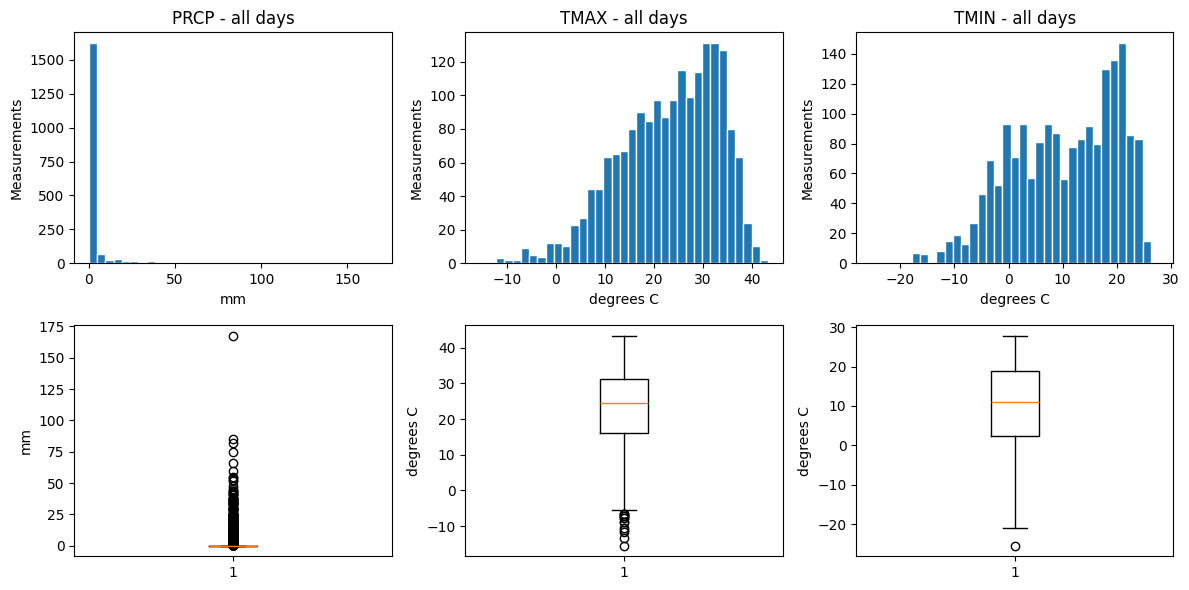

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for col, element in enumerate(["PRCP", "TMAX", "TMIN"]):
    values = daily.loc[daily["event_type"].eq(element), "severity_value"].dropna()
    unit = "mm" if element == "PRCP" else "degrees C"
    axes[0, col].hist(values, bins=35, edgecolor="white")
    axes[0, col].set_title(element + " - all days")
    axes[0, col].set_xlabel(unit)
    axes[0, col].set_ylabel("Measurements")
    axes[1, col].boxplot(values)
    axes[1, col].set_ylabel(unit)
plt.tight_layout()
plt.show()

## 4. Seasonality and precipitation populations

Positive reported precipitation means PRCP >0 mm, not a validated climatological
wet-day threshold; provider trace flags remain in the input attributes. Both
the full daily series and the positive subset are reported. Month-specific
temperature summaries help identify the limits of pooled-year flags.

,station,element,month,n,median,skewness,excess_kurtosis,iqr_flags,zscore_flags
0,USW00013967,PRCP,1,155,0.0,3.596840,12.737728,NaN,5
1,USW00013967,PRCP,2,141,0.0,3.884245,16.679456,NaN,3
2,USW00013967,PRCP,3,155,0.0,4.487256,21.208764,NaN,6
3,USW00013967,PRCP,4,150,0.0,3.124234,10.109137,31.0,5
4,USW00013967,PRCP,5,155,0.0,2.728673,7.120140,30.0,6
5,USW00013967,PRCP,6,150,0.0,3.677788,14.906345,33.0,3
6,USW00013967,PRCP,7,155,0.0,4.988019,29.374528,NaN,5
7,USW00013967,PRCP,8,155,0.0,9.934685,109.417609,NaN,1
8,USW00013967,PRCP,9,150,0.0,6.636791,47.306338,NaN,3
9,USW00013967,PRCP,10,155,0.0,3.757271,13.653226,NaN,7


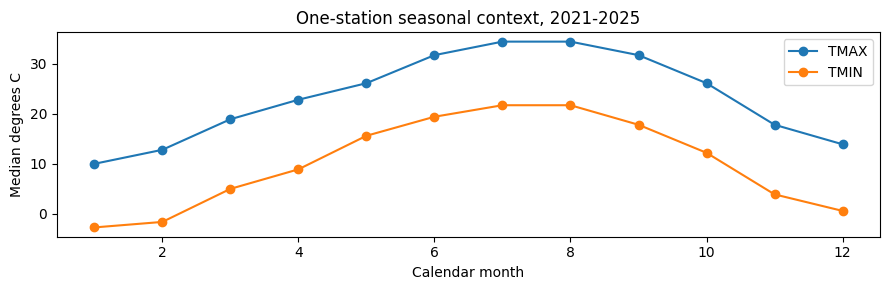

In [10]:
seasonal = []
for (station, element, month), group in daily.groupby(["station", "event_type", daily["date"].dt.month]):
    seasonal.append({"station": station, "element": element, "month": month, **profile(group["severity_value"])})
seasonal = pd.DataFrame(seasonal)
display(seasonal[["station", "element", "month", "n", "median", "skewness", "excess_kurtosis", "iqr_flags", "zscore_flags"]])
fig, ax = plt.subplots(figsize=(9, 3))
for element in ["TMAX", "TMIN"]:
    series = daily[daily["event_type"].eq(element)].groupby(daily["date"].dt.month)["severity_value"].median()
    ax.plot(series.index, series.values, marker="o", label=element)
ax.set(xlabel="Calendar month", ylabel="Median degrees C", title="One-station seasonal context, 2021-2025")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Relationships and curation decisions

Pearson and Spearman are calculated on the same complete station dates.
Correlation is an association, not causation, prediction or evidence that an
extreme value should be removed. No feature selection or model is fitted.

Aligned complete dates: 1826


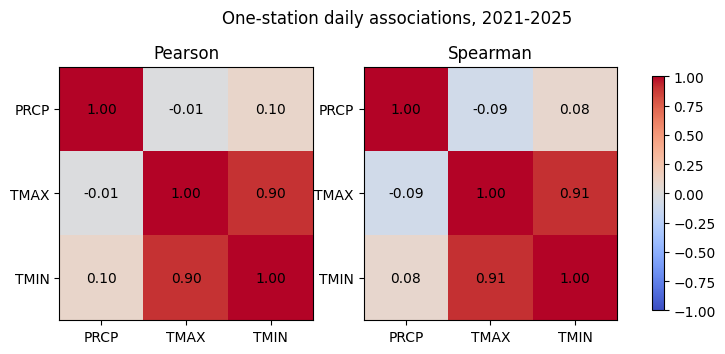

event_type,PRCP,TMAX,TMIN
event_type,,,
PRCP,1.000000,-0.011117,0.098779
TMAX,-0.011117,1.000000,0.902845
TMIN,0.098779,0.902845,1.000000


event_type,PRCP,TMAX,TMIN
event_type,,,
PRCP,1.000000,-0.092730,0.078794
TMAX,-0.092730,1.000000,0.906358
TMIN,0.078794,0.906358,1.000000


In [11]:
paired = wide.dropna()
pearson = paired.corr(method="pearson")
spearman = paired.corr(method="spearman")
print("Aligned complete dates:", len(paired))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, matrix, title in zip(axes, [pearson, spearman], ["Pearson", "Spearman"]):
    image = ax.imshow(matrix, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(3), matrix.columns); ax.set_yticks(range(3), matrix.index)
    for row in range(3):
        for col in range(3): ax.text(col, row, f"{matrix.iloc[row, col]:.2f}", ha="center", va="center")
    ax.set_title(title)
fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.8)
fig.suptitle("One-station daily associations, 2021-2025")
plt.show()
display(pearson); display(spearman)

### Treatment experiment on a copy

The class demonstrates P5-P95 clipping and log1p. For hazard monitoring, clipping
may suppress the extremes we want to retain. We quantify that effect on a copy,
then retain the original values. The transformation below is an analytical
experiment, not a new source capture, a replacement Silver dataset or a model.

,experiment,p5_mm,p95_mm,changed_measurements,measurements,original_max_mm,trial_max_mm,original_total_mm,trial_total_mm,decision
0,P5-P95 clipping on a copy,0.0,16.3,91,1826,167.4,16.3,4373.7,2819.6,Not applied: retain recorded extremes and phys...


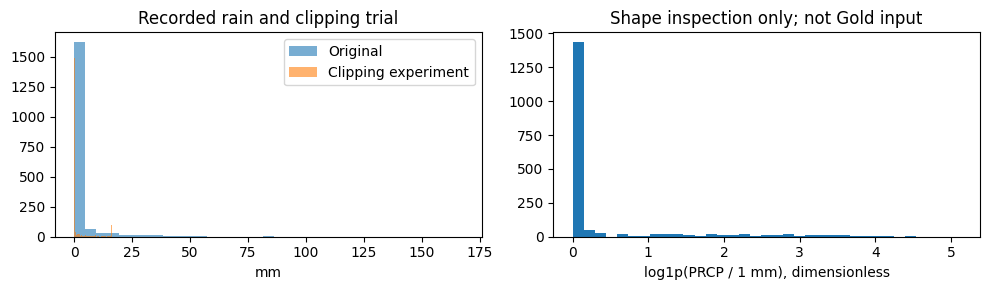

,finding,decision
0,Repeated exports,Reconcile by source/key and reviewed lineage; ...
1,Source-inapplicable nulls,Keep explicit time grain; no global median/KNN...
2,Missing storm point/magnitude,Keep source evidence and completeness metrics;...
3,Zero-heavy and right-skewed PRCP,Separate all-day and positive-rain review; zer...
4,Seasonal temperature / rare extremes,Use monthly context; retain flags without removal
5,Automatic profiling warnings,Review with source/unit/key semantics; warning...


In [12]:
precipitation = wide["PRCP"].dropna()
p5, p95 = precipitation.quantile([0.05, 0.95])
clipped_trial = precipitation.clip(lower=p5, upper=p95)
log_trial = np.log1p(precipitation)
clipping_review = pd.DataFrame([{
    "experiment": "P5-P95 clipping on a copy", "p5_mm": p5, "p95_mm": p95,
    "changed_measurements": int(clipped_trial.ne(precipitation).sum()),
    "measurements": len(precipitation), "original_max_mm": precipitation.max(),
    "trial_max_mm": clipped_trial.max(), "original_total_mm": precipitation.sum(),
    "trial_total_mm": clipped_trial.sum(),
    "decision": "Not applied: retain recorded extremes and physical totals"}])
display(clipping_review)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(precipitation, bins=35, alpha=0.6, label="Original")
axes[0].hist(clipped_trial, bins=35, alpha=0.6, label="Clipping experiment")
axes[0].set(xlabel="mm", title="Recorded rain and clipping trial"); axes[0].legend()
axes[1].hist(log_trial, bins=35)
axes[1].set(xlabel="log1p(PRCP / 1 mm), dimensionless", title="Shape inspection only; not Gold input")
plt.tight_layout(); plt.show()
pd.testing.assert_series_equal(wide["PRCP"].dropna(), precipitation)
curation_decisions = pd.DataFrame([
    {"finding": "Repeated exports", "decision": "Reconcile by source/key and reviewed lineage; do not count snapshots twice"},
    {"finding": "Source-inapplicable nulls", "decision": "Keep explicit time grain; no global median/KNN filling"},
    {"finding": "Missing storm point/magnitude", "decision": "Keep source evidence and completeness metrics; no invented point or zero"},
    {"finding": "Zero-heavy and right-skewed PRCP", "decision": "Separate all-day and positive-rain review; zero-IQR method unavailable"},
    {"finding": "Seasonal temperature / rare extremes", "decision": "Use monthly context; retain flags without removal"},
    {"finding": "Automatic profiling warnings", "decision": "Review with source/unit/key semantics; warnings are not validated errors"},
])
display(curation_decisions)

## 6. Narrative quality and lexical tone

The registered NOAA Oklahoma 2021 source supplies event or episode narratives.
We retain original text and source identity, and score original English text with
VADER 3.3.2. The score describes lexical tone, not hazard severity. Other years
have no portable text Silver in this delivery; no labelled validation exists.

,text_field,characters,sentiment_score,sentiment_label
count,1324,1324.000000,1324.000000,1324
unique,2,NaN,NaN,3
top,EPISODE_NARRATIVE,NaN,NaN,neutral
freq,692,NaN,NaN,456
mean,NaN,280.526435,0.011959,NaN
std,NaN,307.761091,0.450719,NaN
min,NaN,13.000000,-0.990700,NaN
25%,NaN,102.750000,-0.318200,NaN
50%,NaN,177.000000,0.000000,NaN
75%,NaN,336.000000,0.421500,NaN


sentiment_label
negative    423
neutral     456
positive    445
Name: records, dtype: int64

,keyword,mentions
0,th,895
1,oklahoma,812
2,wind,595
3,drought,444
4,county,394
5,reported,350
6,hail,346
7,afternoon,345
8,developed,339
9,thunderstorms,327


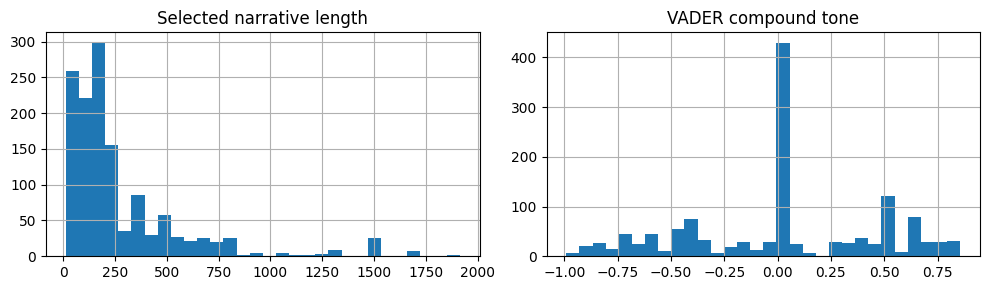

In [13]:
text_manifest = json.loads((root / "workshop_3/samples/silver_text/noaa_oklahoma_2021_text.manifest.json").read_text())
text_path = root / text_manifest["path"]
assert hashlib.sha256(text_path.read_bytes()).hexdigest().upper() == text_manifest["sha256"]
texts = pd.read_parquet(text_path)
assert len(texts) == text_manifest["rows"] == 1324
assert texts.source_key.is_unique and texts.raw_text.notna().all()
display(texts[["text_field", "characters", "sentiment_score", "sentiment_label"]].describe(include="all"))
display(texts.groupby("sentiment_label").size().rename("records"))
from collections import Counter
display(pd.DataFrame(Counter(t for tokens in texts.tokens for t in tokens).most_common(12), columns=["keyword", "mentions"]))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
texts.characters.hist(bins=30, ax=axes[0]); axes[0].set_title("Selected narrative length")
texts.sentiment_score.hist(bins=30, ax=axes[1]); axes[1].set_title("VADER compound tone")
plt.tight_layout(); plt.show()

## 7. Automatic profiling as in class

`ProfileReport` complements the manual audit. The station report uses actual
daily dates and three measurements. A separate source-quality projection shows
missingness without pooling incompatible event magnitudes or profiling numeric
database IDs. Duplicate warnings in that projection do not define source identity.
Open the saved HTML reports; findings still require a source-aware decision.

In [14]:
from ydata_profiling import ProfileReport
from IPython.display import FileLink
profile_dir = root / "workshop_3/profiling"
profile_dir.mkdir(parents=True, exist_ok=True)
station_profile = ProfileReport(
    wide.reset_index(), title="GHCN USW00013967 - daily Silver quality, 2021-2025",
    explorative=True, pool_size=1, progress_bar=False,
    correlations={"pearson": {"calculate": True}, "spearman": {"calculate": True},
                  "kendall": {"calculate": False}, "phi_k": {"calculate": False},
                  "cramers": {"calculate": True}},
    missing_diagrams={"bar": True, "matrix": True, "heatmap": True})
station_profile_path = profile_dir / "ghcn_station_quality.html"
station_profile.to_file(station_profile_path)
station_description = json.loads(station_profile.to_json())
assert station_description["table"]["n"] == len(wide)
display(FileLink("../workshop_3/profiling/ghcn_station_quality.html"))

D:\usuarios\Monitores\AppData\Local\Temp\ipykernel_5984\1420392428.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


  0%|          | 0/4 [00:00<?, ?it/s]

100%|██████████| 4/4 [00:00<00:00, 204.56it/s]

D:\usuarios\Monitores\Desktop\Documentos Kevin\Universidad\Programacion para analisis de datos\Multi-Hazard Weather Impact Monitoring\workshop_3\profiling\ghcn_station_quality.html

In [15]:
quality_projection = canonical[["source", "event_type", "observed_date", "observed_at_utc",
                                "latitude", "longitude"]].copy()
quality_projection["observed_date"] = pd.to_datetime(quality_projection["observed_date"])
quality_projection["observed_at_utc"] = pd.to_datetime(quality_projection["observed_at_utc"], utc=True).dt.tz_localize(None)
quality_projection["magnitude_missing"] = canonical["severity_value"].isna()
source_profile = ProfileReport(
    quality_projection, title="Silver source/time/point completeness - reviewed canonical records",
    explorative=True, pool_size=1, progress_bar=False,
    correlations={"auto": {"calculate": False}, "pearson": {"calculate": False},
                  "spearman": {"calculate": False}, "cramers": {"calculate": False}},
    interactions={"continuous": False},
    missing_diagrams={"bar": True, "matrix": True, "heatmap": True})
source_profile_path = profile_dir / "silver_source_quality.html"
source_profile.to_file(source_profile_path)
source_description = json.loads(source_profile.to_json())
assert source_description["table"]["n"] == len(canonical)
display(FileLink("../workshop_3/profiling/silver_source_quality.html"))

  0%|          | 0/7 [00:00<?, ?it/s]

 86%|████████▌ | 6/7 [00:00<00:00, 55.12it/s]

100%|██████████| 7/7 [00:00<00:00, 59.90it/s]

D:\usuarios\Monitores\Desktop\Documentos Kevin\Universidad\Programacion para analisis de datos\Multi-Hazard Weather Impact Monitoring\workshop_3\profiling\silver_source_quality.html

## 8. Save the evidence and hand off

The reviewed Silver register and production Gold remain unchanged. The new
tables, profiling reports and figures document the course-aligned quality review.
Dashboard layout, interactive filters, forecasting/feature-selection experiments,
CHI and model evaluation are outside this notebook. No classroom toy-data result
is presented as a finding about Oklahoma.

In [16]:
import importlib.metadata
for name, frame in {"distribution_review": summary, "seasonal_review": seasonal,
                    "missingness": null_report, "quality_checks": checks,
                    "class_statistics": class_statistics, "pearson": pearson,
                    "spearman": spearman, "clipping_experiment": clipping_review,
                    "curation_decisions": curation_decisions}.items():
    frame.to_csv(out / (name + ".csv"), index=name in ["pearson", "spearman"], lineterminator=chr(10))
assert hashlib.sha256(frozen_register_path.read_bytes()).hexdigest().upper() == frozen_register_sha256
profiles = {}
for name, path, description in [("station", station_profile_path, station_description),
                                ("source_quality", source_profile_path, source_description)]:
    profiles[name] = {"path": path.relative_to(root).as_posix(),
                      "sha256": hashlib.sha256(path.read_bytes()).hexdigest().upper(),
                      "rows": description["table"]["n"], "columns": description["table"]["n_var"],
                      "alerts": [str(alert) for alert in description.get("alerts", [])]}
audit = {"input_sha256": hashes, "frozen_input_register_sha256": frozen_register_sha256,
         "verified_exports": len(files), "snapshot_rows": len(raw),
         "unique_source_records": len(canonical), "source_counts": {str(k): int(v) for k,v in canonical.groupby("source").size().items()},
         "station_dates": len(wide), "complete_paired_dates": len(paired),
         "quality_checks": checks.to_dict(orient="records"), "clipping_experiment": clipping_review.to_dict(orient="records"),
         "profiles": profiles, "weather_requests": False, "raw_or_silver_changed": False,
         "class_methods": "scipy.stats.skew(), scipy.stats.kurtosis(), Pandas std() and quantile(); IQR 1.5 and absolute Z-score >3",
         "gold_methods": "Equivalent Spark skewness/excess kurtosis; sample std and linear quartiles",
         "versions": {name: importlib.metadata.version(name) for name in ["pandas", "numpy", "scipy", "matplotlib", "ydata-profiling"]}}
(out / "course_eda_review.json").write_text(json.dumps(audit, indent=2) + "\n", encoding="utf-8", newline="\n")
print("Evidence saved:", out)
print("Original source records preserved:", len(canonical))

Evidence saved: D:\usuarios\Monitores\Desktop\Documentos Kevin\Universidad\Programacion para analisis de datos\Multi-Hazard Weather Impact Monitoring\workshop_3\evidence\eda_20261124
Original source records preserved: 19039
